# DCGAN(Deep Convolutional Generative Adversarial Network)

DCGAN은 기존 GAN의 완전연결층(Fully Connected Layer)을 합성곱 신경망(CNN) 기반 구조로 확장한 생성 모델이다.

앞서 구현한 GAN에서는 `nn.Linear()`를 이용하여 MNIST 이미지를 생성하였다. DCGAN에서는 `nn.ConvTranspose2d()`로 이미지를 생성하고, `nn.Conv2d()`로 진짜 이미지와 가짜 이미지를 판별한다.

## 1. GAN과 DCGAN의 차이

| 구분            | GAN (기본 구현)     | DCGAN                  |
| ------------- | --------------- | ---------------------- |
| Generator     | `nn.Linear()`   | `nn.ConvTranspose2d()` |
| Discriminator | `nn.Linear()`   | `nn.Conv2d()`          |
| 이미지 처리        | 784차원 벡터        | 2차원 공간 구조 유지           |
| 공간적 특징 학습     | 제한적             | 합성곱을 통해 학습             |
| 주요 활성화 함수     | LeakyReLU, Tanh | ReLU, LeakyReLU, Tanh  |
| 정규화           | 선택적             | BatchNorm 주로 사용        |
| 생성 품질         | 구조에 따라 제한적      | 이미지 생성에 적합한 구조         |

DCGAN도 GAN의 한 종류이므로 Generator와 Discriminator가 경쟁적으로 학습하는 원리는 동일하다.

## 2. DCGAN 전체 구조

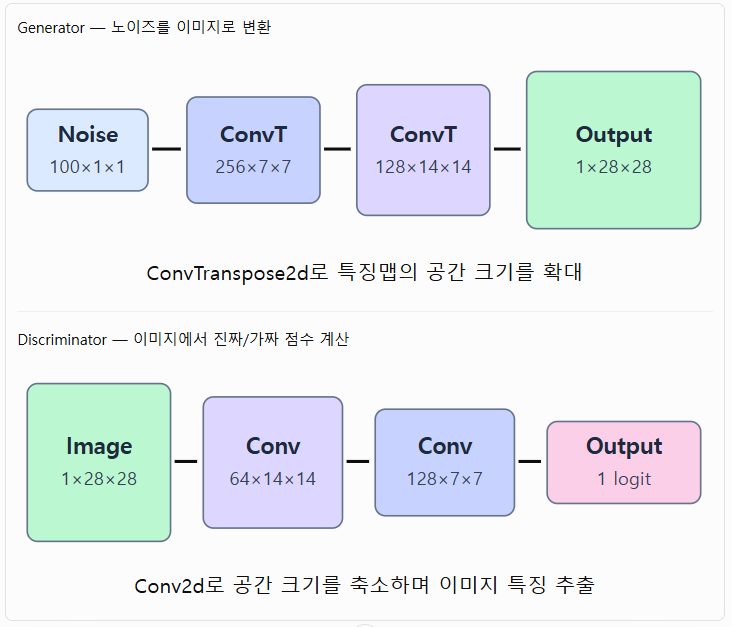

## 3. PyTorch DCGAN 구현 — MNIST

기존 GAN과 동일하게 MNIST 28×28 이미지를 사용한다. 비교 실험을 위해 배치 크기, 학습률, Epoch를 동일하게 설정할 수 있다.

## 4. GAN과 DCGAN 비교 실습

앞서 학습한 기본 GAN의 결과와 DCGAN의 결과를 동일한 조건에서 비교하면 다음 항목을 평가할 수 있다.

| 평가 항목            | 기본 GAN   | DCGAN    |
| ---------------- | -------- | -------- |
| 생성 이미지 선명도       | 실제 결과 기록 | 실제 결과 기록 |
| 배경 노이즈           | 실제 결과 기록 | 실제 결과 기록 |
| 숫자 다양성           | 실제 결과 기록 | 실제 결과 기록 |
| Mode Collapse 여부 | 추가 검증    | 추가 검증    |
| G Loss / D Loss  | 기존 그래프   | 새 그래프    |
| 학습 시간            | 측정 필요    | 측정 필요    |

DCGAN은 이미지의 공간적 특징을 활용하므로 기본 GAN보다 좋은 이미지를 생성할 가능성이 있지만, 모든 실험에서 품질 향상이 보장되는 것은 아니다.

실습 검증: 위 코드는 MNIST의 28×28 입력과 각 합성곱 계층의 출력 차원이 일치하도록 구성하였다. 다만 전체 학습을 직접 실행한 결과는 아니므로 실제 손실 변화와 생성 품질은 실행 후 확인해야 한다.

### 핵심 정리

- `ConvTranspose2d`: Generator에서 작은 특징맵을 큰 이미지로 변환한다.
- `Conv2d`: Discriminator에서 이미지의 공간적 특징을 추출한다.
- `BatchNorm2d`: 중간 특징값의 분포를 정규화하여 학습을 돕는다.
- `LeakyReLU`: 음수 입력에서도 작은 기울기를 유지한다.
- `Tanh`: 최종 생성 이미지의 픽셀값을 -1\~1 범위로 제한한다.

기본 GAN에서 DCGAN으로 전환할 때 가장 중요한 변화는 784차원으로 펼친 픽셀 벡터 대신 이미지의 2차원 공간 구조를 유지하면서 생성과 판별을 수행한다는 점이다.

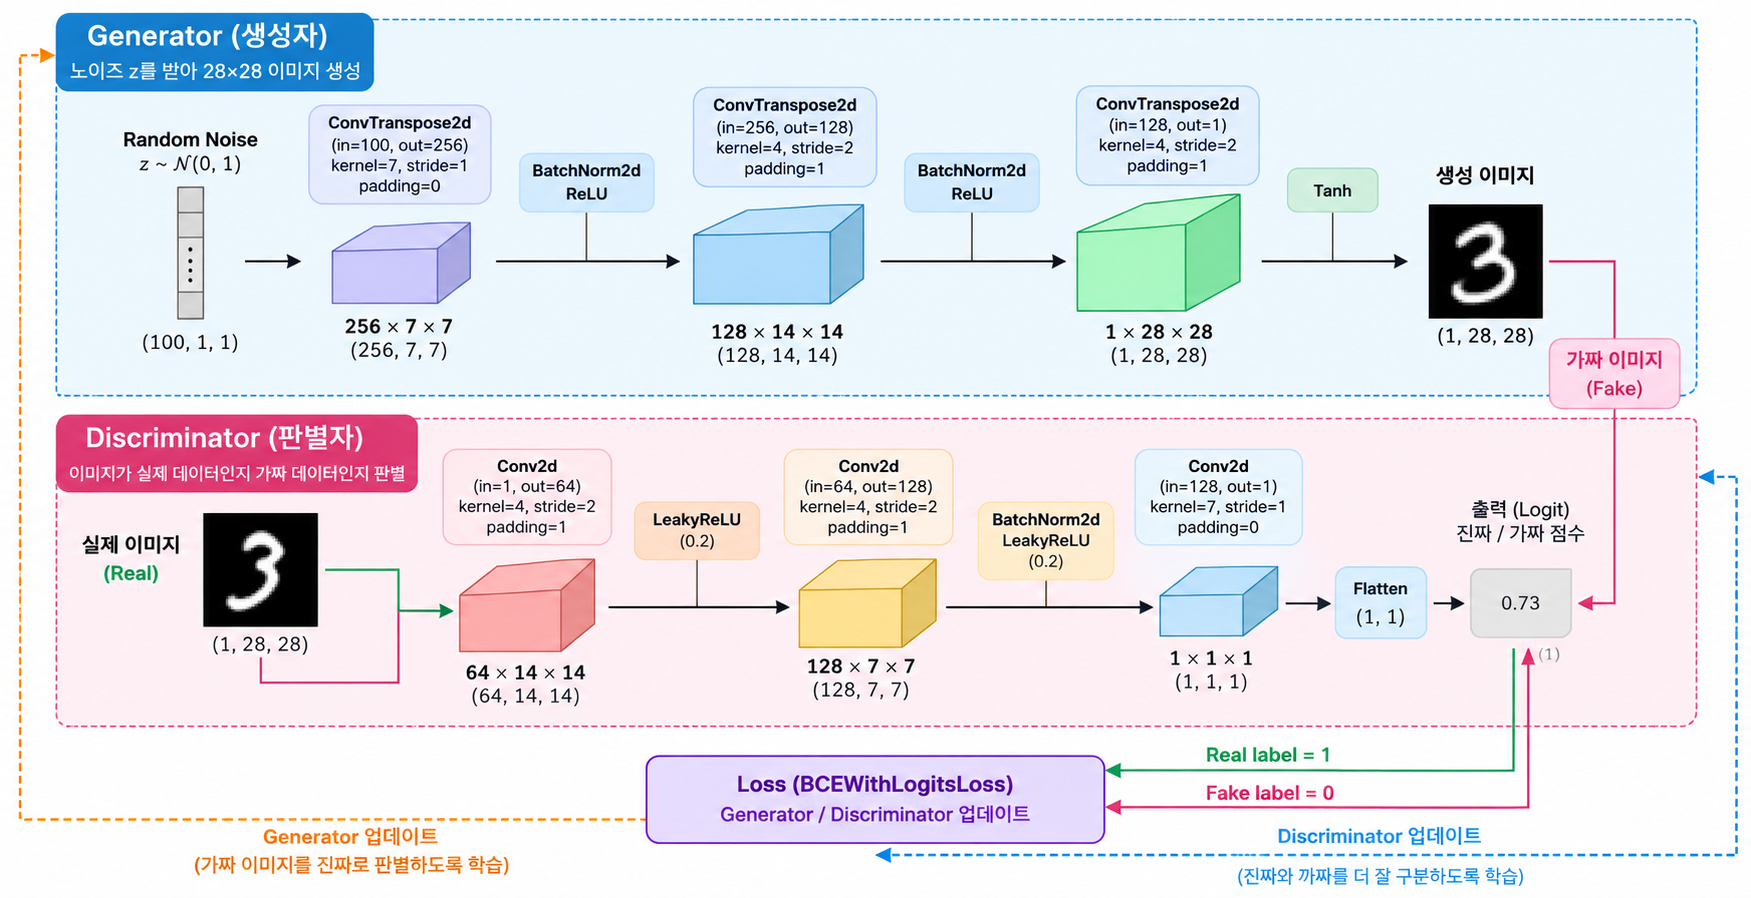

Epoch [1/20] D Loss: 0.8650 | G Loss: 1.5865
Epoch [2/20] D Loss: 0.8877 | G Loss: 1.2925
Epoch [3/20] D Loss: 0.9500 | G Loss: 1.2113
Epoch [4/20] D Loss: 0.9411 | G Loss: 1.2329
Epoch [5/20] D Loss: 0.9350 | G Loss: 1.2451
Epoch [6/20] D Loss: 0.9433 | G Loss: 1.2350
Epoch [7/20] D Loss: 0.9715 | G Loss: 1.2497
Epoch [8/20] D Loss: 0.9425 | G Loss: 1.2420
Epoch [9/20] D Loss: 0.9332 | G Loss: 1.2922
Epoch [10/20] D Loss: 0.9474 | G Loss: 1.2867
Epoch [11/20] D Loss: 0.9233 | G Loss: 1.3162
Epoch [12/20] D Loss: 0.8990 | G Loss: 1.3522
Epoch [13/20] D Loss: 0.9251 | G Loss: 1.3417
Epoch [14/20] D Loss: 0.9302 | G Loss: 1.3477
Epoch [15/20] D Loss: 0.8993 | G Loss: 1.3778
Epoch [16/20] D Loss: 0.9225 | G Loss: 1.3741
Epoch [17/20] D Loss: 0.9212 | G Loss: 1.3785
Epoch [18/20] D Loss: 0.8733 | G Loss: 1.4231
Epoch [19/20] D Loss: 0.9153 | G Loss: 1.4043
Epoch [20/20] D Loss: 0.8981 | G Loss: 1.4263


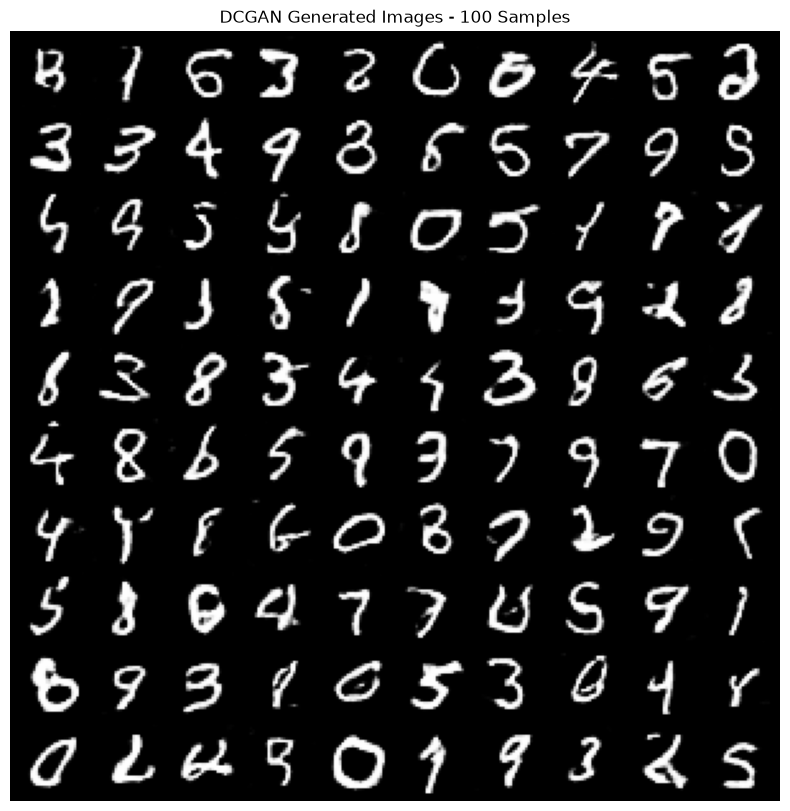

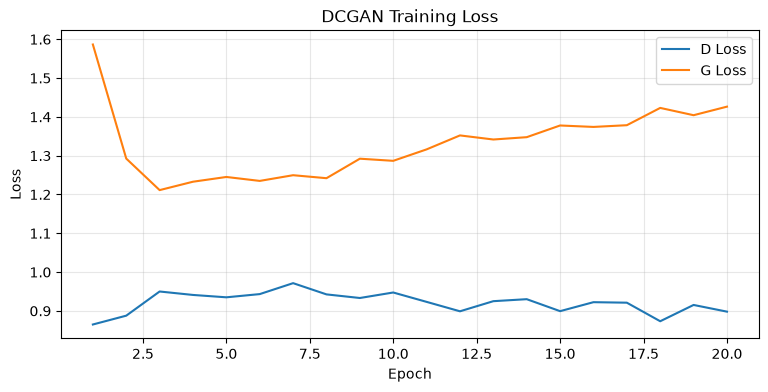

In [ ]:
# ------------------------------------------------------------------------
# 1 데이터 및 환경 설정
# ---------------------------------------------------------------------------
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torch.utils.data import DataLoader

# CUDA, MPS, CPU 자동 선택
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(42)

LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS = 20
LR = 0.0002

# 이미지를 [-1, 1] 범위로 정규화한다.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# MNIST 데이터셋
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)


# ------------------------------------------------------------
# 2 Generator 구현
# ------------------------------------------------------------
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            # 입력: (B, 100, 1, 1)
            # 출력: (B, 256, 7, 7)
            nn.ConvTranspose2d(
                LATENT_DIM, 256,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # 입력: (B, 256, 7, 7)
            # 출력: (B, 128, 14, 14)
            nn.ConvTranspose2d(
                256, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 입력: (B, 128, 14, 14)
            # 출력: (B, 1, 28, 28)
            nn.ConvTranspose2d(
                128, 1,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            # 픽셀 범위를 [-1, 1]로 제한한다.
            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z)


# -------------------------------------------------------
# 3 Discriminator 구현
# ------------------------------------------------------
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            # 입력: (B, 1, 28, 28)
            # 출력: (B, 64, 14, 14)
            nn.Conv2d(
                1, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # 입력: (B, 64, 14, 14)
            # 출력: (B, 128, 7, 7)
            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # 입력: (B, 128, 7, 7)
            # 출력: (B, 1, 1, 1)
            nn.Conv2d(
                128, 1,
                kernel_size=7,
                stride=1,
                padding=0
            )
            # BCEWithLogitsLoss를 사용하므로
            # Sigmoid를 추가하지 않는다.
        )

    def forward(self, x):
        # (B, 1, 1, 1) → (B, 1)
        return self.model(x).reshape(-1, 1)

# ---------------------------------------------------------
# 4 모델 및 옵티마이저 초기화
# -----------------------------------------------------------
# DCGAN에서 자주 사용하는 가중치 초기화
def weights_init(m):
    classname = m.__class__.__name__

    # Conv 계열 가중치 초기화
    if "Conv" in classname:
        # nn.init : PyTorch의 가중치 초기화 모듈
        # normal_ : 정규분포에서 난수를 생성항여 텐서를 직접 변경
        # m.wight.data : 해당 계층의 가능한 가중치
        # 0.0 : 정규분포의 평균(mean)
        # 0.02 : 정규분포의 표준편차(std)
        nn.init.normal_(m.weight.data, 0.0, 0.02)

    # BatchNorm 가중치와 편향 초기화
    elif "BatchNorm" in classname:
        # 1.0 : 정규분포의 평균(mean)
        # 0.02 : 정규분포의 표준편차(std)
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        # nn.init : PyTorch의 bias의 초기화 모듈
        # constant_ : 상수값
        # m.bias.data : 해당 계층의 가능한 편향
        # 0 : 0으로 초기화
        nn.init.constant_(m.bias.data, 0)

# 모델 생성
G = Generator().to(device)
D = Discriminator().to(device)

# 초기화 적용
G.apply(weights_init)
D.apply(weights_init)

# 손실함수
criterion = nn.BCEWithLogitsLoss()

# 두 모델의 옵티마이저
optimizer_G = torch.optim.Adam(
    G.parameters(), lr=LR, betas=(0.5, 0.999)
)
optimizer_D = torch.optim.Adam(
    D.parameters(), lr=LR, betas=(0.5, 0.999)
)

# 손실 저장
g_losses = []
d_losses = []

# 학습 경과 비교용 고정 노이즈
fixed_noise = torch.randn(
    16, LATENT_DIM, 1, 1, device=device
)      




# ------------------------------------------------------------------
# 5 DCGAN 학습
# -------------------------------------------------------------------
for epoch in range(EPOCHS):
    G.train()
    D.train()

    total_g_loss = 0.0
    total_d_loss = 0.0

    for real_images, _ in train_loader:
        # 실제 이미지를 학습 장치로 이동한다.
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # 실제 이미지: 1, 가짜 이미지: 0
        real_labels = torch.ones(
            batch_size, 1, device=device
        )
        fake_labels = torch.zeros(
            batch_size, 1, device=device
        )

        # ----------------------------------
        # 1. Discriminator 학습
        # ----------------------------------
        optimizer_D.zero_grad()

        # 실제 이미지에 대한 손실
        real_outputs = D(real_images)
        d_real_loss = criterion(
            real_outputs, real_labels
        )

        # 가짜 이미지 생성
        z = torch.randn(
            batch_size, LATENT_DIM, 1, 1,
            device=device
        )
        fake_images = G(z)

        # detach()로 Generator의 그래프를 분리한다.
        fake_outputs = D(fake_images.detach())
        d_fake_loss = criterion(
            fake_outputs, fake_labels
        )

        # 판별자의 전체 손실
        d_loss = d_real_loss + d_fake_loss

        # 판별자 역전파 및 가중치 업데이트
        d_loss.backward()
        optimizer_D.step()

        # ----------------------------------
        # 2. Generator 학습
        # ----------------------------------
        optimizer_G.zero_grad()

        # 새로운 노이즈 생성
        z = torch.randn(
            batch_size, LATENT_DIM, 1, 1,
            device=device
        )

        # 새로운 가짜 이미지 생성
        fake_images = G(z)

        # Generator 학습 중에는
        # Discriminator의 파라미터 기울기를 비활성화한다.
        for p in D.parameters():
            p.requires_grad_(False)

        # 가짜 이미지를 진짜로 판별하도록 학습한다.
        fake_outputs = D(fake_images)
        g_loss = criterion(
            fake_outputs, real_labels
        )

        # Generator로 기울기 전달
        g_loss.backward()
        optimizer_G.step()

        # 다음 배치의 D 학습을 위해 다시 활성화한다.
        for p in D.parameters():
            p.requires_grad_(True)

        # 손실 기록
        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    # 에폭 평균 손실 계산
    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    d_losses.append(avg_d_loss)
    g_losses.append(avg_g_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"D Loss: {avg_d_loss:.4f} | "
        f"G Loss: {avg_g_loss:.4f}"
    )



# ----------------------------------------------------------------------------
# 6. 생성 이미지 100장 시각화
# ------------------------------------------------------------------------------
# Generator 평가 모드
G.eval()

# 서로 다른 노이즈 100개 생성
z = torch.randn(
    100, LATENT_DIM, 1, 1,
    device=device
)

# 생성 이미지 추론
with torch.inference_mode():
    fake_images = G(z)

    # GAN의 Generator 마지막 계층에는 일반적으로 Tanh() 활성화 함수를 사용한다
    # Tanh() 활성화 함수는 [-1,1]의 범위 값을 갖는다
    # 생성된 fake_images을 plt.imshow()으로 시각화할때는 픽셀값을 [0,1]범위로 맞추는 것이 일반적이다.
    # [-1, 1] → [0, 1]
    fake_images = (fake_images + 1) / 2

# 10 × 10 격자 구성
grid = make_grid(
    # fake_images를 plt.immshow()으로 시각화 할때 텐서를 CPU로 이동한다.
    fake_images.cpu(),
    nrow=10,
    padding=2
)

# 결과 시각화
plt.figure(figsize=(10, 10))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title("DCGAN Generated Images - 100 Samples")
plt.axis("off")
plt.show()


# ----------------------------------------------------------------------
# 7.손실 그래프 시각화
# ------------------------------------------------------------------------
plt.figure(figsize=(9, 4))

plt.plot(
    range(1, EPOCHS + 1),
    d_losses,
    label="D Loss"
)
plt.plot(
    range(1, EPOCHS + 1),
    g_losses,
    label="G Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
